### Description 
Explore the Netflix dataset to uncover trends, patterns, and insights.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../../data/cleaned/dataset_cleaned.csv')
df.shape

(8790, 12)

In [19]:
df.head(5)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,US,2021-09-25,2020,PG-13,90 min,Documentaries,90,minutes
1,s3,TV Show,Ganglands,Julien Leclercq,FR,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,seasons
2,s6,TV Show,Midnight Mass,Mike Flanagan,US,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,seasons
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,BR,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,minutes
4,s8,Movie,Sankofa,Haile Gerima,US,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,minutes


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   show_id         8790 non-null   object
 1   type            8790 non-null   object
 2   title           8790 non-null   object
 3   director        8790 non-null   object
 4   country         8789 non-null   object
 5   date_added      8790 non-null   object
 6   release_year    8790 non-null   int64 
 7   rating          8790 non-null   object
 8   duration        8790 non-null   object
 9   listed_in       8790 non-null   object
 10  duration_value  8790 non-null   int64 
 11  duration_unit   8790 non-null   object
dtypes: int64(2), object(10)
memory usage: 824.2+ KB


In [21]:
df.isnull().sum()

show_id           0
type              0
title             0
director          0
country           1
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
duration_value    0
duration_unit     0
dtype: int64

In [22]:
df.describe()

,release_year,duration_value
count,8790.000000,8790.000000
mean,2014.183163,69.934471
std,8.825466,50.794433
min,1925.000000,1.000000
25%,2013.000000,2.000000
50%,2017.000000,88.500000
75%,2019.000000,106.000000
max,2021.000000,312.000000


In [23]:
#distrution Tv show vs movies
repartition=df['type'].value_counts()
percentage=df['type'].value_counts(normalize=True)*100
bilan =pd.DataFrame({'Total': repartition, 'Percentage (%)': percentage})
print(bilan.round(2))

         Total  Percentage (%)
type                          
Movie     6126           69.69
TV Show   2664           30.31


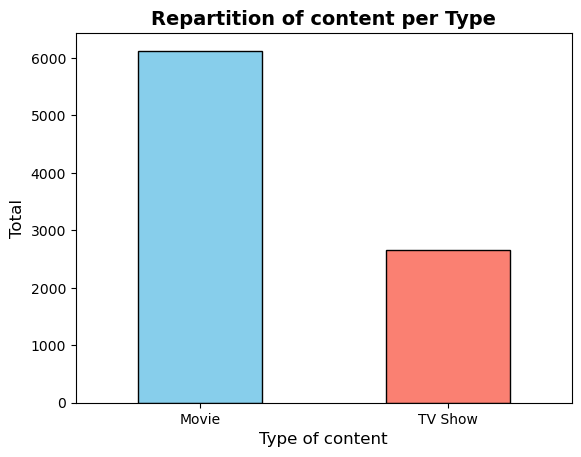

In [24]:
repartition = df['type'].value_counts()

repartition.plot(kind='bar', color=['skyblue', 'salmon'], edgecolor='black')
plt.title("Repartition of content per Type", fontsize=14, fontweight='bold')
plt.xlabel("Type of content", fontsize=12)
plt.ylabel("Total", fontsize=12)
plt.xticks(rotation=0)
plt.show()

In [25]:
repartition=df['country'].value_counts()
percentage=df['country'].value_counts(normalize=True)*100
bilan =pd.DataFrame({'Total': repartition, 'Percentage (%)': percentage})
print(bilan.round(2))

          Total  Percentage (%)
country                        
US         3240           36.86
IN         1057           12.03
UK          638            7.26
PK          421            4.79
Unknown     287            3.27
...         ...             ...
ZW            1            0.01
Cameroon      1            0.01
GR            1            0.01
SU            1            0.01
IR            1            0.01

[84 rows x 2 columns]


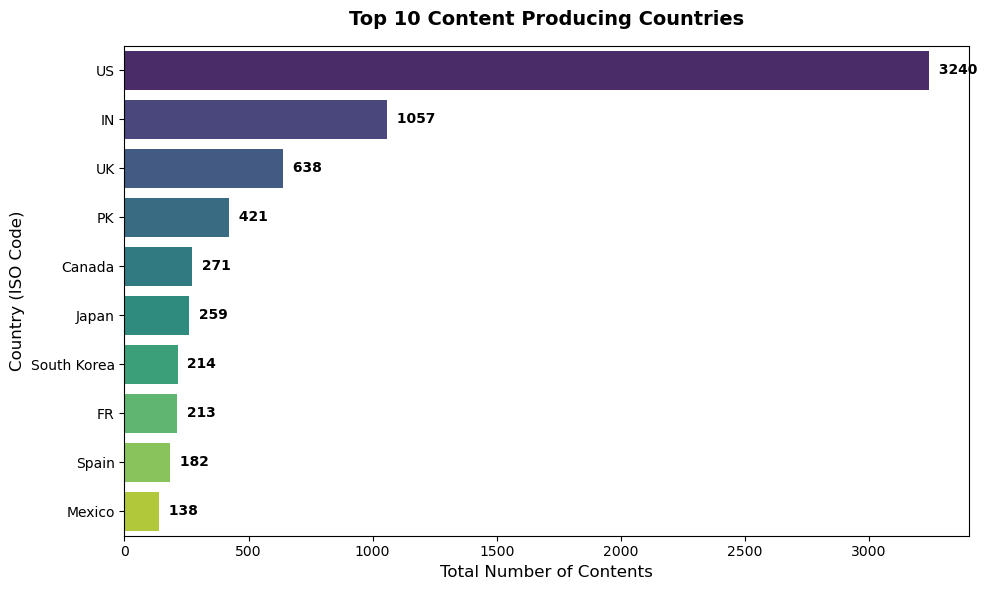

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Preparation (Filter out 'Unknown' and select the Top 10 countries)
# If you are starting directly from your cleaned DataFrame:
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)

# 2. Initialize the matplotlib figure size
plt.figure(figsize=(10, 6))

# 3. Create the horizontal bar plot (x = counts, y = country codes)
sns.barplot(
    x=top_countries.values, 
    y=top_countries.index, 
    palette="viridis", 
    hue=top_countries.index, 
    legend=False
)

# 4. Add data labels (the exact numbers) at the end of each bar
for index, value in enumerate(top_countries.values):
    plt.text(value + 20, index, f" {value}", va='center', fontsize=10, fontweight='bold')

# 5. Customize the chart aesthetics (Labels and Titles)
plt.title("Top 10 Content Producing Countries", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Number of Contents", fontsize=12)
plt.ylabel("Country (ISO Code)", fontsize=12)

# Adjust layout to make sure labels fit properly without getting cut off
plt.tight_layout()
plt.show()